In [262]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipynbname
from scipy.stats import ttest_rel
pd.set_option('display.max_columns', None)

In [139]:
folder_path = str(ipynbname.path().parent) + "/../"
print(folder_path)

/Genomics/argo/users/yz8667/Autism_network_integration/scripts/Integration/../


# General (run this cell first)

In [342]:
def calculate_statistics(df, neg, wt, mut1, mut2=None, mut3=None, bar_width = 0.65, figsize = (10, 3.5)):
    # -----------------------------
    # p-value → star
    # -----------------------------
    def p_to_star(p):
        if p < 0.001:
            return "***"
        elif p < 0.01:
            return "**"
        elif p < 0.05:
            return "*"
        else:
            return "ns"
    
    vector2color = {neg:"#BDBDBD", wt: "#2CA6C4", mut1: "#E64B35"}
    ordered_vectors = [neg, wt, mut1]
    if mut2 is not None:
        vector2color[mut2] = "#E64B35"
        ordered_vectors.append(mut2)
    if mut3 is not None:
        vector2color[mut3] = "#E64B35"
        ordered_vectors.append(mut3)
    
    # calculate technical mean for each biological replicate.
    bio_groups = {f"Bio{i+1}": df.columns[i*3:(i+1)*3] for i in range(df.shape[1] // 3)}
    bio_rep_means = pd.DataFrame({
        bio: df[cols].mean(axis=1) for bio, cols in bio_groups.items()
    })
    display(bio_rep_means)

    # -----------------------------
    # calculate bar heights and error bars (mean ± SD or SEM)
    group_means = bio_rep_means.mean(axis=1)
    group_sd = bio_rep_means.std(axis=1, ddof=1)
    group_sem = group_sd / np.sqrt(bio_rep_means.shape[1])

    yerr = group_sd
    # yerr = group_sem

    # -----------------------------
    # plotting
    # -----------------------------
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(group_means))
    bars = ax.bar(x, [group_means[vec] for vec in ordered_vectors], yerr=[yerr[vec] for vec in ordered_vectors],
        capsize=6,
        width=bar_width,
        edgecolor="black",
        linewidth=1.2,
        color=[vector2color[vec] for vec in ordered_vectors]
    )

    # -----------------------------
    # scatter（biological replicates）
    # -----------------------------
    n_rep = bio_rep_means.shape[1]
    jitter_width = 0.18  # total spread around each bar center
    jitter = np.linspace(-jitter_width, jitter_width, n_rep)
    for i, group in enumerate(ordered_vectors):
        yvals = bio_rep_means.loc[group].values.astype(float)
        ax.scatter(
            np.full_like(yvals, x[i], dtype=float) + jitter[:len(yvals)],
            yvals,
            color="black",
            s=45,
            zorder=3
        )

    # -----------------------------
    # paired connecting lines
    # -----------------------------
    for j in range(bio_rep_means.shape[1]):
        yvals = [bio_rep_means.loc[group, bio_rep_means.columns[j]] for group in ordered_vectors]
        xvals = x + jitter[j]
        ax.plot(xvals, yvals,
            color="black",
            alpha=1,
            linewidth=0.4,
            zorder=2
        )

    # -----------------------------
    # axes
    # -----------------------------
    ax.set_xticks(x)
    ax.set_xticklabels([""] * len(x))  # not writing group names on x-axis, using legend instead
    ax.set_ylabel("Luciferase")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # -----------------------------
    # legend（using bars to generate legend）
    # -----------------------------
    ax.legend(
        bars,
        ordered_vectors,
        frameon=False,
        loc='center left',
        bbox_to_anchor=(1.02, 0.5)
    )

    # -----------------------------
    #  calculate p values: using paired t-test, because the three biological replicates are paired
    # -----------------------------
    neg = bio_rep_means.loc[neg].values.astype(float)
    wt = bio_rep_means.loc[wt].values.astype(float)
    mut1 = bio_rep_means.loc[mut1].values.astype(float)
    if mut2 is not None:
        mut2 = bio_rep_means.loc[mut2].values.astype(float)
    if mut3 is not None:
        mut3 = bio_rep_means.loc[mut3].values.astype(float)

    p_neg_vs_wt = ttest_rel(neg, wt).pvalue
    p_wt_vs_mut1 = ttest_rel(wt, mut1).pvalue
    if mut2 is not None:
        p_wt_vs_mut2 = ttest_rel(wt, mut2).pvalue
    if mut3 is not None:
        p_wt_vs_mut3 = ttest_rel(wt, mut3).pvalue

    print("\np-values:")
    print(f"Negative vs WT: {p_neg_vs_wt:.4g}", p_to_star(p_neg_vs_wt))
    print(f"WT vs Mutant:   {p_wt_vs_mut1:.4g}", p_to_star(p_wt_vs_mut1))
    if mut2 is not None:
        print(f"WT vs Mutant2:  {p_wt_vs_mut2:.4g}", p_to_star(p_wt_vs_mut2))
    if mut3 is not None:
        print(f"WT vs Mutant3:  {p_wt_vs_mut3:.4g}", p_to_star(p_wt_vs_mut3))

    ymax = max(
        np.max(bio_rep_means.values),  # all scatter points
        np.max(group_means + yerr)     # bar + error
    )
    ax.set_ylim(0, ymax * 1.5)

    plt.tight_layout()
    plt.show()


# General information about experimental candidates

## Old result

In [132]:
df = pd.read_excel("/Genomics/argo/users/yz8667/Autism_network_integration/data/obsolete/gene_discovery.xlsx")
df = df[df["gene"].isin(["LDB1", "PER1", "TCF4", "IQGAP1", "JUN", "ZBTB20"])]
df[["gene", "FDR_TADA.upgraded_ASD"]]

,gene,FDR_TADA.upgraded_ASD
1151,TCF4,0.000009
1833,IQGAP1,0.045801
2024,LDB1,0.066233
2358,ZBTB20,0.000001
4098,PER1,0.207367
10371,JUN,0.037404


## SFARI gene list

In [149]:
folder_path = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/"

In [150]:
df_sfari = pd.read_csv(f"{folder_path}/ref/SFARI_GeneList/SFARI-Gene_genes_03-22-2026release_03-23-2026export.csv")
df_sfari[df_sfari["gene-symbol"].isin(["IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"])]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
593,9,LDB1,LIM domain binding 1,ENSG00000198728,10,Rare Single Gene Mutation,1.0,0,4.0,4
812,9,PER1,period homolog 1 (Drosophila),ENSG00000179094,17,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,10
1111,9,TCF4,Transcription factor 4,ENSG00000196628,18,"Rare Single Gene Mutation, Syndromic, Genetic ...",1.0,1,13.5,82
1228,9,ZBTB20,Zinc finger and BTB domain containing 20,ENSG00000181722,3,"Rare Single Gene Mutation, Syndromic",1.0,1,NaN,32


In [154]:
df_sfari = pd.read_csv(f"{folder_path}/ref/SFARI_GeneList/SFARI_genes_04-03-2025release_05-20-2025export.csv")
df_sfari[df_sfari["gene-symbol"].isin(["IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"])]

,status,gene-symbol,gene-name,ensembl-id,chromosome,genetic-category,gene-score,syndromic,eagle,number-of-reports
578,9,LDB1,LIM domain binding 1,ENSG00000198728,10,Rare Single Gene Mutation,1.0,0,4.0,4
791,9,PER1,period homolog 1 (Drosophila),ENSG00000179094,17,"Rare Single Gene Mutation, Genetic Association",2.0,0,NaN,10
1081,9,TCF4,Transcription factor 4,ENSG00000196628,18,"Rare Single Gene Mutation, Syndromic, Genetic ...",1.0,1,13.5,79
1199,9,ZBTB20,Zinc finger and BTB domain containing 20,ENSG00000181722,3,"Rare Single Gene Mutation, Syndromic",1.0,1,NaN,32


## FuRawSup11 + UCSF noncoding

In [127]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRawSup11_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df[["gene", "FDR_TADA_ASD", "p_TADA_ASD", "BF_ASD_EM", "BF_ASD", "FDR_TADA_ASD_AddEM", "p_TADA_ASD_AddEM"]])

####################### in_floor = TRUE


,gene,FDR_TADA_ASD,p_TADA_ASD,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
1151,TCF4,0.001804,0.000009,16.241995,26801.700025,0.000084,2.826861e-07
1833,IQGAP1,0.698656,0.102078,2.815613,6.128033,0.465373,3.322656e-02
2024,LDB1,0.120905,0.002072,1.009725,38.211461,0.125336,2.637837e-03
2358,ZBTB20,0.000298,0.000001,20.251628,183724.224973,0.000015,3.981481e-08
4098,PER1,0.365694,0.015168,1.198526,11.085551,0.329585,1.490135e-02
10371,JUN,0.811888,0.241422,1.563528,2.074219,0.711885,1.389793e-01


####################### in_floor = FALSE


,gene,FDR_TADA_ASD,p_TADA_ASD,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
1151,TCF4,0.001804,0.000009,16.241995,26801.700025,0.000086,2.879144e-07
1833,IQGAP1,0.698656,0.102078,2.815613,6.128033,0.464385,3.273065e-02
2024,LDB1,0.120905,0.002072,1.009725,38.211461,0.126253,2.647187e-03
2358,ZBTB20,0.000298,0.000001,20.251628,183724.224973,0.000014,3.547277e-08
4098,PER1,0.365694,0.015168,1.198526,11.085551,0.329831,1.479910e-02
10371,JUN,0.811888,0.241422,1.563528,2.074219,0.711546,1.371432e-01


## FuRawSup5 + FuRawSup6 + UCSF noncoding

In [125]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_ASC+SSC_SPARK_Combined_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,2623.856197,16.241995,42616.659916,0.000074,2.606197e-07
1833,ENSG00000140575,IQGAP1,9.301225,2.815613,26.188652,0.174710,6.241365e-03
2024,ENSG00000198728,LDB1,95.634057,1.009725,96.564145,0.054713,9.671100e-04
2358,ENSG00000181722,ZBTB20,201.482652,20.251628,4080.351741,0.000671,3.413457e-06
4098,ENSG00000179094,PER1,4.651518,1.198526,5.574966,0.480705,4.958033e-02
10371,ENSG00000177606,JUN,1.349340,1.563528,2.109731,0.684112,1.539333e-01


####################### in_floor = FALSE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,1524.147319,16.241995,24755.193524,0.000108,3.614049e-07
1833,ENSG00000140575,IQGAP1,5.606359,2.815613,15.785340,0.242529,8.402006e-03
2024,ENSG00000198728,LDB1,86.091290,1.009725,86.928570,0.055989,7.874490e-04
2358,ENSG00000181722,ZBTB20,109.366593,20.251628,2214.851571,0.001555,8.045311e-06
4098,ENSG00000179094,PER1,3.021374,1.198526,3.621196,0.575631,6.150749e-02
10371,ENSG00000177606,JUN,0.474459,1.563528,0.741830,0.901095,9.269065e-01


## FuRawSup5 + UCSF noncoding

In [128]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_ASC+SSC_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,67.672755,16.241995,1099.140571,0.002491,0.000008
1833,ENSG00000140575,IQGAP1,4.178767,2.815613,11.765791,0.319980,0.007752
2024,ENSG00000198728,LDB1,90.236264,1.009725,91.113856,0.052502,0.000404
2358,ENSG00000181722,ZBTB20,196.005296,20.251628,3969.426360,0.000766,0.000002
4098,ENSG00000179094,PER1,2.586847,1.198526,3.100403,0.636732,0.052552
10371,ENSG00000177606,JUN,1.171774,1.563528,1.832101,0.750069,0.111233


####################### in_floor = FALSE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,67.672755,16.241995,1099.140571,0.002217,0.000007
1833,ENSG00000140575,IQGAP1,3.436505,2.815613,9.675870,0.369544,0.009288
2024,ENSG00000198728,LDB1,81.232112,1.009725,82.022134,0.053123,0.000377
2358,ENSG00000181722,ZBTB20,150.942417,20.251628,3056.829697,0.001014,0.000003
4098,ENSG00000179094,PER1,1.680276,1.198526,2.013854,0.730095,0.082507
10371,ENSG00000177606,JUN,0.652225,1.563528,1.019772,0.896919,0.507492


## FuRawSup6 + UCSF noncoding

In [129]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_SPARK_noncoding_UCSF_Combined_Simple_roulette_rd_control_formatted_260503_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,38.772711,16.241995,629.746191,0.005973,0.000017
1833,ENSG00000140575,IQGAP1,2.225830,2.815613,6.267077,0.513079,0.024093
2024,ENSG00000198728,LDB1,1.059818,1.009725,1.070126,0.886257,0.488210
2358,ENSG00000181722,ZBTB20,1.027945,20.251628,20.817559,0.223151,0.003462
4098,ENSG00000179094,PER1,1.798142,1.198526,2.155121,0.722686,0.090119
10371,ENSG00000177606,JUN,1.151537,1.563528,1.800459,0.763989,0.122830


####################### in_floor = FALSE


,gene_id,gene,bf_coding,bf_noncoding,bf,fdr,pval
1151,ENSG00000196628,TCF4,22.522318,16.241995,365.807383,0.011536,0.000035
1833,ENSG00000140575,IQGAP1,1.631413,2.815613,4.593428,0.567738,0.027768
2024,ENSG00000198728,LDB1,1.059818,1.009725,1.070126,0.884434,0.392901
2358,ENSG00000181722,ZBTB20,0.724558,20.251628,14.673487,0.283681,0.004788
4098,ENSG00000179094,PER1,1.798142,1.198526,2.155121,0.728946,0.078131
10371,ENSG00000177606,JUN,0.727447,1.563528,1.137383,0.870962,0.316681


## FuRawSup5 + FuRawSup6

In [ ]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_ASC+SSC_SPARK_Combined_CodingOnly_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,bf_asc_ssc,bf_spark,bf,fdr,pval
1151,ENSG00000196628,TCF4,67.672755,38.772711,2623.856197,0.001347,0.000007
1833,ENSG00000140575,IQGAP1,4.178767,2.225830,9.301225,0.371991,0.021925
2024,ENSG00000198728,LDB1,90.236264,1.059818,95.634057,0.052369,0.000768
2358,ENSG00000181722,ZBTB20,196.005296,1.027945,201.482652,0.019671,0.000203
4098,ENSG00000179094,PER1,2.586847,1.798142,4.651518,0.514968,0.049429
10371,ENSG00000177606,JUN,1.171774,1.151537,1.349340,0.796037,0.279704


####################### in_floor = FALSE


,gene_id,gene,bf_asc_ssc,bf_spark,bf,fdr,pval
1151,ENSG00000196628,TCF4,67.672755,22.522318,1524.147319,0.002221,0.000011
1833,ENSG00000140575,IQGAP1,3.436505,1.631413,5.606359,0.481778,0.030531
2024,ENSG00000198728,LDB1,81.232112,1.059818,86.091290,0.051893,0.000611
2358,ENSG00000181722,ZBTB20,150.942417,0.724558,109.366593,0.037082,0.000387
4098,ENSG00000179094,PER1,1.680276,1.798142,3.021374,0.613255,0.062920
10371,ENSG00000177606,JUN,0.652225,0.727447,0.474459,0.911974,0.969374


## FuRawSup5

In [160]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_ASC+SSC_CodingOnly_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
1151,ENSG00000196628,TCF4,0.217,0.999810,64.600354,1.000000,1.0,1.020709,1.0,1.026306,67.672755,0.072294,0.000525
1833,ENSG00000140575,IQGAP1,0.275,0.997540,1.000000,2.780474,1.0,1.502897,1.0,1.000000,4.178767,0.572849,0.027050
2024,ENSG00000198728,LDB1,0.291,0.985290,65.855261,1.000000,1.0,1.370221,1.0,1.000000,90.236264,0.047092,0.000283
2358,ENSG00000181722,ZBTB20,0.317,0.973820,56.571735,1.000000,1.0,2.794080,1.0,1.240022,196.005296,0.015741,0.000069
4098,ENSG00000179094,PER1,0.466,0.000293,2.586847,1.000000,1.0,1.000000,1.0,1.000000,2.586847,0.661829,0.045676
10371,ENSG00000177606,JUN,1.020,0.059620,1.000000,1.000000,1.0,1.000000,1.0,1.171774,1.171774,0.862115,0.241692


####################### in_floor = FALSE


,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
1151,ENSG00000196628,TCF4,0.217,0.999810,64.600354,1.000000,1.0,1.020709,1.0,1.026306,67.672755,0.065702,0.000416
1833,ENSG00000140575,IQGAP1,0.275,0.997540,1.000000,2.780474,1.0,1.502897,1.0,0.822373,3.436505,0.607605,0.028643
2024,ENSG00000198728,LDB1,0.291,0.985290,65.855261,1.000000,1.0,1.370221,1.0,0.900216,81.232112,0.051063,0.000293
2358,ENSG00000181722,ZBTB20,0.317,0.973820,56.571735,0.770094,1.0,2.794080,1.0,1.240022,150.942417,0.021742,0.000098
4098,ENSG00000179094,PER1,0.466,0.000293,2.586847,0.649546,1.0,1.000000,1.0,1.000000,1.680276,0.760437,0.076875
10371,ENSG00000177606,JUN,1.020,0.059620,1.000000,1.000000,1.0,0.556614,1.0,1.171774,0.652225,0.929699,0.959247


## FuRawSup6

In [161]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/data/TADA/output/InhAll_DNVAll/"
for in_floor in ["TRUE", "FALSE"]:
    print(f"####################### in_floor = {in_floor}")
    df = pd.read_csv(dr + f"TADA_coding_FuRaw_SPARK_CodingOnly_infloor{in_floor}_ScaleByLOEUF.txt", sep = "\t")
    df = df[df["gene"].isin({"IQGAP1", "ZBTB20", "JUN", "TCF4", "LDB1", "PER1"})]
    display(df)

####################### in_floor = TRUE


,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
1151,ENSG00000196628,TCF4,0.217,0.999810,6.011513,1.000000,4.868123,1.324893,1.0,1.000000,38.772711,0.143573,0.001197
1833,ENSG00000140575,IQGAP1,0.275,0.997540,1.000000,1.000000,1.000000,1.888391,1.0,1.178691,2.225830,0.713452,0.061263
2024,ENSG00000198728,LDB1,0.291,0.985290,1.000000,1.000000,1.000000,1.042158,1.0,1.016946,1.059818,0.890228,0.377550
2358,ENSG00000181722,ZBTB20,0.317,0.973820,1.000000,1.000000,1.000000,1.000000,1.0,1.027945,1.027945,0.897412,0.434677
4098,ENSG00000179094,PER1,0.466,0.000293,1.000000,1.798142,1.000000,1.000000,1.0,1.000000,1.798142,0.757298,0.084194
10371,ENSG00000177606,JUN,1.020,0.059620,1.000000,1.000000,1.000000,1.000000,1.0,1.151537,1.151537,0.871241,0.274659


####################### in_floor = FALSE


,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
1151,ENSG00000196628,TCF4,0.217,0.999810,6.011513,0.649782,4.868123,1.324893,1.0,0.893962,22.522318,0.204744,0.001963
1833,ENSG00000140575,IQGAP1,0.275,0.997540,1.000000,0.732946,1.000000,1.888391,1.0,1.178691,1.631413,0.784932,0.089414
2024,ENSG00000198728,LDB1,0.291,0.985290,1.000000,1.000000,1.000000,1.042158,1.0,1.016946,1.059818,0.888299,0.308770
2358,ENSG00000181722,ZBTB20,0.317,0.973820,1.000000,0.750565,1.000000,0.939107,1.0,1.027945,0.724558,0.929279,0.928624
4098,ENSG00000179094,PER1,0.466,0.000293,1.000000,1.798142,1.000000,1.000000,1.0,1.000000,1.798142,0.762088,0.074049
10371,ENSG00000177606,JUN,1.020,0.059620,1.000000,1.000000,1.000000,0.631718,1.0,1.151537,0.727447,0.929253,0.927883


## NetFlow3D significantly interconnected modules

In [ ]:
dr = ""

# TCF4 and ZBTB20

In [250]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/raw_data/Experiments/"
df1 = pd.read_excel(dr + "260504_Z_T_renilla_1.xlsx")
df1 = df1.dropna(subset = ["Unnamed: 0"])
df1 = df1.drop(columns = ["Unnamed: 4", "Unnamed: 8"])
df1 = df1.rename(columns = {"Unnamed: 0": "vector"}).set_index("vector")
df1

,1,2,3,5,6,7,9,10,11
vector,,,,,,,,,
ZBTB20-EGFP,4266,2019,2772,4340,4425,3705,1088,1431,1241
ZBTB20-eZBTB20,3617,3711,3311,2971,2890,2864,5210,5107,5147
ZBTB20-eZBTB20-mut1: (chr3: 114893370:T/G),4186,3294,3854,5946,5191,6779,3111,2957,3096
ZBTB20-eZBTB20-mut2 (chr3: 114893176:T/G),1557,1786,2019,3395,2681,3135,3349,3079,3396
ZBTB20-eZBTB20-mut3 (chr3: 114893142:T/G),6203,5725,5936,5703,7181,6096,2892,3651,2607
TCF4-EGFP,2591,2209,3050,5312,6088,6665,4093,3596,4612
TCF4-eTCF4,2822,4051,3317,2512,3766,3286,2510,2565,2579
TCF4-eTCF4-mut (chr18:55459034:T/A),2330,1778,2782,4111,4164,4997,2004,2155,1947


In [251]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/raw_data/Experiments/"
df2 = pd.read_excel(dr + "260504_Z_T_Firefly.xlsx", )
df2 = df2.drop(columns = ["Unnamed: 4", "Unnamed: 8"])
df2 = df2.dropna(subset = ["Unnamed: 0"])
df2 = df2.rename(columns = {"Unnamed: 0": "vector"}).set_index("vector")
df2

,1,2,3,5,6,7,9,10,11
vector,,,,,,,,,
ZBTB20-EGFP,6171,6300,6043,6468,6217,6050,3129,2845,3345
ZBTB20-eZBTB20,8442,8555,8321,6850,7395,6838,13836,13768,15473
ZBTB20-eZBTB20-mut1: (chr3: 114893370:T/G),8808,7855,8846,14029,13697,13642,8575,8617,9060
ZBTB20-eZBTB20-mut2 (chr3: 114893176:T/G),7211,7187,8721,10363,10627,11239,12078,12026,11762
ZBTB20-eZBTB20-mut3 (chr3: 114893142:T/G),11989,11741,11350,12431,13642,13245,5737,5601,5514
TCF4-EGFP,19648,19837,20351,32619,36208,33691,40222,39332,46861
TCF4-eTCF4,48619,51657,51036,41476,41397,45344,45488,48044,48309
TCF4-eTCF4-mut (chr18:55459034:T/A),24218,24018,23431,43652,45983,46378,26249,26725,25717


In [252]:
result = df2 / df1
result = result.rename(columns = {"Unnamed: 0": "vector"})
result

,1,2,3,5,6,7,9,10,11
vector,,,,,,,,,
ZBTB20-EGFP,1.446554,3.120357,2.180014,1.490323,1.404972,1.632928,2.875919,1.98812,2.695407
ZBTB20-eZBTB20,2.333978,2.305309,2.513138,2.305621,2.558824,2.38757,2.655662,2.695908,3.006217
ZBTB20-eZBTB20-mut1: (chr3: 114893370:T/G),2.104157,2.384639,2.295278,2.359401,2.638605,2.012391,2.756348,2.914102,2.926357
ZBTB20-eZBTB20-mut2 (chr3: 114893176:T/G),4.631342,4.024076,4.319465,3.05243,3.963819,3.585008,3.60645,3.905814,3.463486
ZBTB20-eZBTB20-mut3 (chr3: 114893142:T/G),1.932774,2.05083,1.912062,2.17973,1.899735,2.172736,1.983748,1.5341,2.115075
TCF4-EGFP,7.583173,8.980081,6.672459,6.140625,5.947438,5.054914,9.827022,10.937709,10.160668
TCF4-eTCF4,17.228561,12.751666,15.386192,16.511146,10.9923,13.799148,18.122709,18.730604,18.731679
TCF4-eTCF4-mut (chr18:55459034:T/A),10.393991,13.508436,8.422358,10.618341,11.042988,9.281169,13.098303,12.401392,13.208526



p-values:
Negative vs WT: 0.2091 ns
WT vs Mutant:   0.5727 ns
WT vs Mutant2:  0.05582 ns
WT vs Mutant3:  0.0907 ns


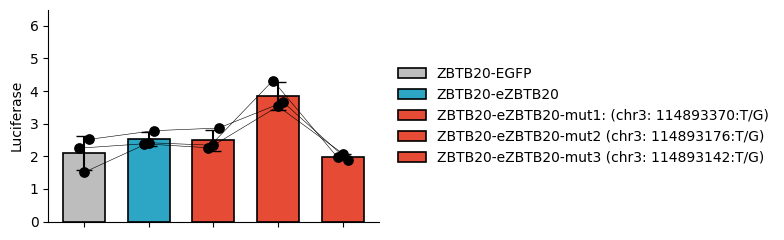

In [253]:
neg = "ZBTB20-EGFP"
wt = "ZBTB20-eZBTB20"
mut1 = "ZBTB20-eZBTB20-mut1: (chr3: 114893370:T/G)"
mut2 = "ZBTB20-eZBTB20-mut2 (chr3: 114893176:T/G)"
mut3 = "ZBTB20-eZBTB20-mut3 (chr3: 114893142:T/G)"
calculate_statistics(result.loc[[neg, wt, mut1, mut2, mut3]], neg = neg, wt = wt, mut1 = mut1, mut2 = mut2, mut3 = mut3, figsize = (8, 2.5))


p-values:
Negative vs WT: 0.001067 **
WT vs Mutant:   0.01927 *


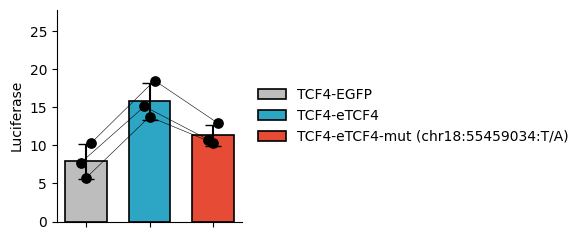

In [247]:
neg = "TCF4-EGFP"
wt = "TCF4-eTCF4"
mut1 = "TCF4-eTCF4-mut (chr18:55459034:T/A)"
calculate_statistics(result.loc[[neg, wt, mut1]], neg = neg, wt = wt, mut1 = mut1, figsize = (6, 2.5))

# IQGAP1

In [211]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/raw_data/Experiments/"
df = pd.read_excel(dr + "260504_IQGAP1_firefly_renilla_luciferase.xlsx", header = None)
df = df.drop(columns = [4,8])
display(df)
df_renilla = df[0:4]
df_renilla.columns = df_renilla.iloc[0]   # set first row as header
df_renilla = df_renilla[1:].reset_index(drop=True)
df_renilla = df_renilla.rename(columns={"renilla": "vector"}).set_index("vector")
df_firefly = df[4:8]
df_firefly.columns = df_firefly.iloc[0]   # set first row as header
df_firefly = df_firefly[1:].reset_index(drop=True)
df_firefly = df_firefly.rename(columns={"firefly": "vector"}).set_index("vector")
display(df_renilla)
display(df_firefly)

,0,1,2,3,5,6,7,9,10,11
0,renilla,bio1,bio1,bio1,bio2,bio2,bio2,bio3,bio3,bio3
1,pIQGAP1-EGFP,425,354,447,555,483,470,641,554,545
2,pIQGAP1-eIQGAP1,506,567,601,495,453,722,911,781,679
3,pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T),435,588,457,372,463,359,1293,1185,1356
4,firefly,bio1,bio1,bio1,bio2,bio2,bio2,bio3,bio3,bio3
5,pIQGAP1-EGFP,498,494,467,667,608,719,686,681,641
6,pIQGAP1-eIQGAP1,6988,6825,6863,5445,5140,5424,10142,10479,10200
7,pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T),3249,3628,3203,2342,2134,2305,8173,8067,8660
8,NaN,tech1,tech2,tech3,tech1,tech2,tech3,tech1,tech2,tech3


,bio1,bio1,bio1,bio2,bio2,bio2,bio3,bio3,bio3
vector,,,,,,,,,
pIQGAP1-EGFP,425,354,447,555,483,470,641,554,545
pIQGAP1-eIQGAP1,506,567,601,495,453,722,911,781,679
pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T),435,588,457,372,463,359,1293,1185,1356


4,bio1,bio1,bio1,bio2,bio2,bio2,bio3,bio3,bio3
vector,,,,,,,,,
pIQGAP1-EGFP,498,494,467,667,608,719,686,681,641
pIQGAP1-eIQGAP1,6988,6825,6863,5445,5140,5424,10142,10479,10200
pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T),3249,3628,3203,2342,2134,2305,8173,8067,8660


In [212]:
df = df_firefly / df_renilla
df.columns = [x + "_" + y for x in ["bio1", "bio2", "bio3"] for y in ["tech1", "tech2", "tech3"]]
df

,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
vector,,,,,,,,,
pIQGAP1-EGFP,1.171765,1.39548,1.044743,1.201802,1.258799,1.529787,1.070203,1.229242,1.176147
pIQGAP1-eIQGAP1,13.810277,12.037037,11.419301,11.0,11.346578,7.512465,11.132821,13.417414,15.022091
pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T),7.468966,6.170068,7.008753,6.295699,4.609071,6.420613,6.320959,6.807595,6.386431



p-values:
Negative vs WT: 0.009233 **
WT vs Mutant:   0.01712 *


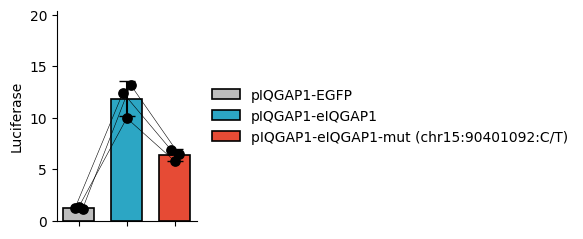

In [216]:
calculate_statistics(df, neg = "pIQGAP1-EGFP", wt = "pIQGAP1-eIQGAP1", mut1 = "pIQGAP1-eIQGAP1-mut (chr15:90401092:C/T)", figsize = (6, 2.5))

# JUN

In [217]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/raw_data/Experiments/"
df = pd.read_excel(dr + "260504_Jun_luciferase.xlsx", header = None)
display(df)

df_firefly = df[0:6]
df_firefly.columns = df_firefly.iloc[0]   # set first row as header
df_firefly = df_firefly[1:].reset_index(drop=True)
df_firefly = df_firefly.rename(columns={"firefly": "vector"}).set_index("vector")
display(df_firefly)

df_renilla = df[6:]
df_renilla.columns = df_renilla.iloc[0]   # set first row as header
df_renilla = df_renilla[1:].reset_index(drop=True)
df_renilla = df_renilla.rename(columns={"renilla": "vector"}).set_index("vector")
display(df_renilla)


,0,1,2,3,4,5,6,7,8,9
0,firefly,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
1,pJun-EGFP,133470,140560,133840,207270,203390,204690,213840,214000,227180
2,pJun-JunE2,111810,103410,103080,30342,32891,29520,46342,42241,46515
3,pJun-JunE2_mut chr1:58781904:T/G,1056700,1048700,1017200,312610,292630,300550,224850,271580,249830
4,pJun-JunE3,540590,518770,493590,418550,408470,407540,376500,358300,394000
5,pJun-JunE3_mut chr1:58783518:G/C,104900,93930,94872,60940,58491,61253,41251,38302,41386
6,renilla,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
7,pJun-EGFP,1689,1475,1303,2016,2609,2419,1950,1319,1447
8,pJun-JunE2,3625,3291,3121,975,1627,949,1120,886,805
9,pJun-JunE2_mut chr1:58781904:T/G,5905,5227,5448,2043,3137,2520,894,1203,1200


,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
vector,,,,,,,,,
pJun-EGFP,133470,140560,133840,207270,203390,204690,213840,214000,227180
pJun-JunE2,111810,103410,103080,30342,32891,29520,46342,42241,46515
pJun-JunE2_mut chr1:58781904:T/G,1056700,1048700,1017200,312610,292630,300550,224850,271580,249830
pJun-JunE3,540590,518770,493590,418550,408470,407540,376500,358300,394000
pJun-JunE3_mut chr1:58783518:G/C,104900,93930,94872,60940,58491,61253,41251,38302,41386


6,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
vector,,,,,,,,,
pJun-EGFP,1689,1475,1303,2016,2609,2419,1950,1319,1447
pJun-JunE2,3625,3291,3121,975,1627,949,1120,886,805
pJun-JunE2_mut chr1:58781904:T/G,5905,5227,5448,2043,3137,2520,894,1203,1200
pJun-JunE3,3168,3928,5037,1763,2265,1812,1447,1309,1177
pJun-JunE3_mut chr1:58783518:G/C,1698,1405,1608,896,1082,1659,1613,507,952


In [218]:
df = df_firefly / df_renilla
df

,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3
vector,,,,,,,,,
pJun-EGFP,79.023091,95.294915,102.716807,102.8125,77.957072,84.617611,109.661538,162.244124,157.000691
pJun-JunE2,30.844138,31.42206,33.027876,31.12,20.215734,31.106428,41.376786,47.676072,57.782609
pJun-JunE2_mut chr1:58781904:T/G,178.950042,200.631337,186.71072,153.015174,93.283392,119.265873,251.510067,225.752286,208.191667
pJun-JunE3,170.640783,132.069756,97.992853,237.407828,180.339956,224.9117,260.193504,273.720397,334.749363
pJun-JunE3_mut chr1:58783518:G/C,61.778563,66.854093,59.0,68.013393,54.058226,36.92164,25.574086,75.546351,43.472689



p-values:
Negative vs WT: 0.0833 ns
WT vs Mutant:   0.08494 ns


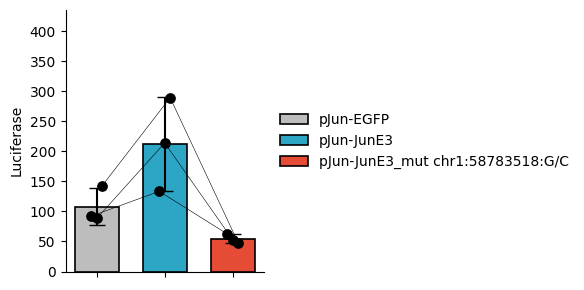

In [222]:
calculate_statistics(df.loc[["pJun-EGFP", "pJun-JunE3", "pJun-JunE3_mut chr1:58783518:G/C"]], "pJun-EGFP", "pJun-JunE3", "pJun-JunE3_mut chr1:58783518:G/C", figsize = (6,3))


p-values:
Negative vs WT: 0.02296 *
WT vs Mutant:   0.03005 *


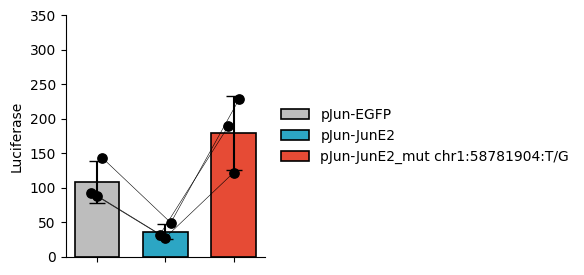

In [226]:
calculate_statistics(df.loc[["pJun-EGFP", "pJun-JunE2", "pJun-JunE2_mut chr1:58781904:T/G"]], "pJun-EGFP", "pJun-JunE2", "pJun-JunE2_mut chr1:58781904:T/G", figsize = (6, 2.8))

# LDB1 and PER1

In [365]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/raw_data/Experiments/"
df = pd.read_excel(dr + "LDB1_PER1_luc.xlsx", header = None)
df = df.dropna(axis=1, how='all')
display(df)

df_firefly_per1 = df[0:4]
df_firefly_per1.columns = df_firefly_per1.iloc[0]   # set first row as header
df_firefly_per1 = df_firefly_per1[1:].reset_index(drop=True)
df_firefly_per1 = df_firefly_per1.dropna(axis=1, how='all')
df_firefly_per1 = df_firefly_per1.rename(columns={"firefly": "vector"}).set_index("vector")
display(df_firefly_per1)

df_renilla_per1 = df[4:8]
df_renilla_per1.columns = df_renilla_per1.iloc[0]   # set first row as header
cols = df_renilla_per1.columns.tolist()
cols[13:22] = ["bio5_tech1", "bio5_tech2", "bio5_tech3", "bio6_tech1", "bio6_tech2", "bio6_tech3", "bio7_tech1", "bio7_tech2", "bio7_tech3"]
df_renilla_per1.columns = cols
df_renilla_per1 = df_renilla_per1[1:].reset_index(drop=True)
df_renilla_per1 = df_renilla_per1.dropna(axis=1, how='all')
df_renilla_per1 = df_renilla_per1.rename(columns={"renilla": "vector"}).set_index("vector")
display(df_renilla_per1)

df_firefly_ldb1 = df[10:14]
df_firefly_ldb1.columns = df_firefly_ldb1.iloc[0]   # set first row as header
df_firefly_ldb1 = df_firefly_ldb1[1:].reset_index(drop=True)
df_firefly_ldb1 = df_firefly_ldb1.dropna(axis=1, how='all')
df_firefly_ldb1 = df_firefly_ldb1.rename(columns={"firefly": "vector"}).set_index("vector")
display(df_firefly_ldb1)

df_renilla_ldb1 = df[14:]
df_renilla_ldb1.columns = df_renilla_ldb1.iloc[0]   # set first row as header
cols = df_renilla_ldb1.columns.tolist()
cols[13:22] = ["bio5_tech1", "bio5_tech2", "bio5_tech3", "bio6_tech1", "bio6_tech2", "bio6_tech3", "bio7_tech1", "bio7_tech2", "bio7_tech3"]
df_renilla_ldb1.columns = cols
df_renilla_ldb1 = df_renilla_ldb1[1:].reset_index(drop=True)
df_renilla_ldb1 = df_renilla_ldb1.dropna(axis=1, how='all')
df_renilla_ldb1 = df_renilla_ldb1.rename(columns={"renilla": "vector"}).set_index("vector")
display(df_renilla_ldb1)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
0,firefly,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3,NaN,NaN,NaN
1,pPER-ePER1,2823,3295,3213,5273,3962,4154,3090,2738,2406,2668,3141,2928,4929,3875,3944,3036,2742,2526,NaN,NaN,NaN
2,pPER1-EGFP,974,1079,1061,1303,1092,1096,1676,1295,1271,965,1031,987,1128,1033,990,1501,1221,1189,NaN,NaN,NaN
3,pPER1-ePER1_mut,2737,2583,2581,3070,2874,2733,3565,3079,2857,2608,2396,2358,2978,2664,2697,3292,2243,2748,NaN,NaN,NaN
4,renilla,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,pPER-ePER1,196,279,592,484,474,471,469,465,465,235,244,533,500,447,430,380,406,429,NaN,NaN,NaN
6,pPER1-EGFP,479,277,390,436,475,493,715,490,501,456,242,417,355,447,432,465,487,419,NaN,NaN,NaN
7,pPER1-ePER1_mut,564,325,293,303,309,260,296,322,568,553,332,263,268,273,211,314,307,591,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3
vector,,,,,,,,,,,,,,,,,,
pPER-ePER1,2823,3295,3213,5273,3962,4154,3090,2738,2406,2668,3141,2928,4929,3875,3944,3036,2742,2526
pPER1-EGFP,974,1079,1061,1303,1092,1096,1676,1295,1271,965,1031,987,1128,1033,990,1501,1221,1189
pPER1-ePER1_mut,2737,2583,2581,3070,2874,2733,3565,3079,2857,2608,2396,2358,2978,2664,2697,3292,2243,2748


,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3
vector,,,,,,,,,,,,,,,,,,
pPER-ePER1,196,279,592,484,474,471,469,465,465,235,244,533,500,447,430,380,406,429
pPER1-EGFP,479,277,390,436,475,493,715,490,501,456,242,417,355,447,432,465,487,419
pPER1-ePER1_mut,564,325,293,303,309,260,296,322,568,553,332,263,268,273,211,314,307,591


10,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3,bio7_tech1,bio7_tech2,bio7_tech3
vector,,,,,,,,,,,,,,,,,,,,,
pLDB1-eLDB1,6543,7176,7286,5861,6188,5491,8275,7791,6902,5751,6954,5657,11687,11294,11609,11319,10792,10834,14028,12347,12576
pLDB1-EGFP,1291,1240,1349,2017,1165,1103,1433,1493,1506,1510,1553,1672,2677,2622,2504,2363,2505,2584,2069,2621,2017
pLDB1-eLDB1_mut,5409,5647,5302,8698,6640,7052,5627,6685,6002,7040,5677,6636,11038,12211,10807,11773,12392,12167,11554,10320,8181


,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3,bio7_tech1,bio7_tech2,bio7_tech3
vector,,,,,,,,,,,,,,,,,,,,,
pLDB1-eLDB1,229,259,219,173,152,216,195,253,208,177,239,215,454,701,324,344,572,343,399,418,452
pLDB1-EGFP,229,363,278,346,215,114,153,195,127,444,376,493,458,325,454,388,377,256,269,725,350
pLDB1-eLDB1_mut,234,242,211,139,133,124,206,221,162,288,347,282,264,352,256,304,353,305,379,401,382


In [366]:
df_ldb1 = df_firefly_ldb1 / df_renilla_ldb1
df_ldb1

10,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3,bio7_tech1,bio7_tech2,bio7_tech3
vector,,,,,,,,,,,,,,,,,,,,,
pLDB1-eLDB1,28.57,27.71,33.27,33.88,40.71,25.42,42.44,30.79,33.18,32.49,29.1,26.31,25.74,16.11,35.83,32.9,18.87,31.59,35.16,29.54,27.82
pLDB1-EGFP,5.638,3.416,4.853,5.829,5.419,9.675,9.366,7.656,11.86,3.401,4.13,3.391,5.845,8.068,5.515,6.09,6.645,10.09,7.691,3.615,5.763
pLDB1-eLDB1_mut,23.12,23.33,25.13,62.58,49.92,56.87,27.32,30.25,37.05,24.44,16.36,23.53,41.81,34.69,42.21,38.73,35.1,39.89,30.49,25.74,21.42


,Bio1,Bio2,Bio3,Bio4,Bio5,Bio6,Bio7
vector,,,,,,,
pLDB1-eLDB1,29.85,33.34,35.47,29.3,25.89,27.79,30.84
pLDB1-EGFP,4.635,6.975,9.627,3.641,6.476,7.61,5.69
pLDB1-eLDB1_mut,23.86,56.46,31.54,21.45,39.57,37.91,25.88



p-values:
Negative vs WT: 5.852e-07 ***
WT vs Mutant:   0.4786 ns


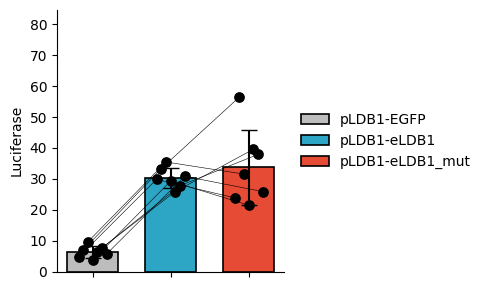

In [367]:
neg = "pLDB1-EGFP"
wt = "pLDB1-eLDB1"
mut1 = "pLDB1-eLDB1_mut"
calculate_statistics(df_ldb1, neg, wt, mut1, figsize = (5,3))

,Bio1,Bio2,Bio3,Bio4
vector,,,,
pLDB1-eLDB1,29.85,35.47,29.3,30.84
pLDB1-EGFP,4.635,9.627,3.641,5.69
pLDB1-eLDB1_mut,23.86,31.54,21.45,25.88



p-values:
Negative vs WT: 6.469e-07 ***
WT vs Mutant:   0.006511 **


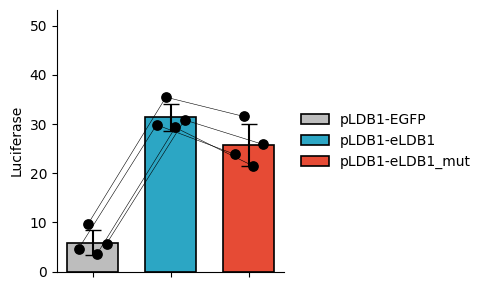

In [362]:
drop_bio = ["bio2", "bio5", "bio6"]
calculate_statistics(df_ldb1.drop(columns = [f"{bio}_tech{i}" for bio in drop_bio for i in range(1, 4)]), neg, wt, mut1, figsize = (5,3))

In [368]:
df_per1 = df_firefly_per1 / df_renilla_per1
df_per1

,bio1_tech1,bio1_tech2,bio1_tech3,bio2_tech1,bio2_tech2,bio2_tech3,bio3_tech1,bio3_tech2,bio3_tech3,bio4_tech1,bio4_tech2,bio4_tech3,bio5_tech1,bio5_tech2,bio5_tech3,bio6_tech1,bio6_tech2,bio6_tech3
vector,,,,,,,,,,,,,,,,,,
pPER-ePER1,14.4,11.81,5.427,10.89,8.359,8.82,6.588,5.888,5.174,11.35,12.87,5.493,9.858,8.669,9.172,7.989,6.754,5.888
pPER1-EGFP,2.033,3.895,2.721,2.989,2.299,2.223,2.344,2.643,2.537,2.116,4.26,2.367,3.177,2.311,2.292,3.228,2.507,2.838
pPER1-ePER1_mut,4.853,7.948,8.809,10.13,9.301,10.51,12.04,9.562,5.03,4.716,7.217,8.966,11.11,9.758,12.78,10.48,7.306,4.65


,Bio1,Bio2,Bio3,Bio4,Bio5,Bio6
vector,,,,,,
pPER-ePER1,10.55,9.358,5.884,9.907,9.233,6.877
pPER1-EGFP,2.883,2.504,2.508,2.914,2.593,2.858
pPER1-ePER1_mut,7.203,9.982,8.879,6.966,11.22,7.48



p-values:
Negative vs WT: 0.0004394 ***
WT vs Mutant:   0.9907 ns


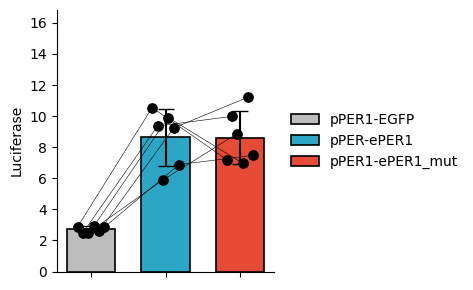

In [374]:
neg = "pPER1-EGFP"
wt = "pPER-ePER1"
mut1 = "pPER1-ePER1_mut"
calculate_statistics(df_per1, neg, wt, mut1, figsize = (5,3))

,Bio1,Bio2
vector,,
pPER-ePER1,10.55,9.907
pPER1-EGFP,2.883,2.914
pPER1-ePER1_mut,7.203,6.966



p-values:
Negative vs WT: 0.02916 *
WT vs Mutant:   0.04081 *


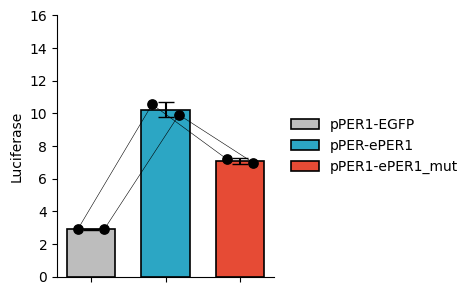

In [373]:
drop_bio = ["bio2", "bio3", "bio5", "bio6"]
calculate_statistics(df_per1.drop(columns = [f"{bio}_tech{i}" for bio in drop_bio for i in range(1, 4)]), neg, wt, mut1, figsize = (5,3))